In [1]:
import sys
sys.path.append("..")

from src.models import RandomFourierFeatures

import torch
from torch.optim import Adam
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Generating Data

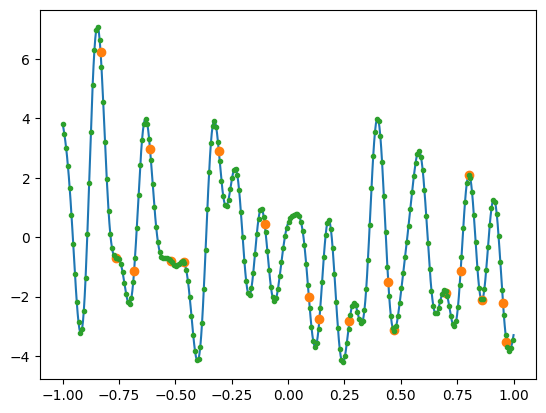

In [2]:
resolution = 512

coords = torch.linspace(-1, 1, resolution)

frequencies = torch.rand(10) * 20*torch.pi
offsets = torch.rand(10) * 2*torch.pi

coss = torch.vstack([torch.cos(coords * freq + offset) for freq, offset in zip(frequencies, offsets)])
combined = torch.sum(coss, dim=0)

test_mask = torch.arange(resolution) % 2 == 0
test_coords = coords[test_mask]
test_values = combined[test_mask]
remaining_coords = coords[~test_mask]
remaining_values = combined[~test_mask]

sparse_mask = torch.bernoulli(torch.ones(remaining_coords.numel()) * 0.1).to(torch.bool)
sparse_coords = remaining_coords[sparse_mask]
sparse_values = remaining_values[sparse_mask]

plt.plot(coords, combined)
plt.plot(sparse_coords, sparse_values, 'o')
plt.plot(test_coords, test_values, '.')

# Fitting on all data

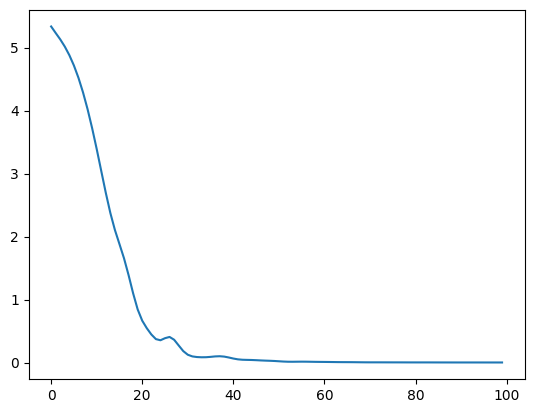

In [3]:
model = RandomFourierFeatures(1, 128, 128, 3, 1, scale=8.0)
optimizer = Adam(params=model.parameters())

epochs = 100
train_losses = torch.zeros(epochs)

inputs = coords.view(-1, 1)
targets = combined.view(-1, 1)
for i in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(inputs)
    loss = F.mse_loss(outputs, targets)
    train_losses[i] = loss.item()
    loss.backward()
    optimizer.step()

plt.plot(train_losses)

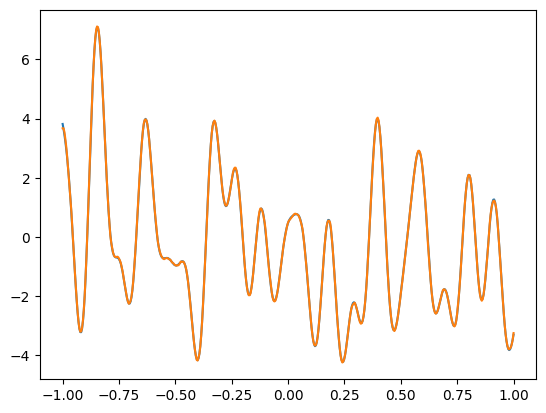

In [4]:
outputs = model(inputs).detach()


plt.plot(coords, combined)
plt.plot(coords, outputs.view(512))

# Fitting on sparse samples

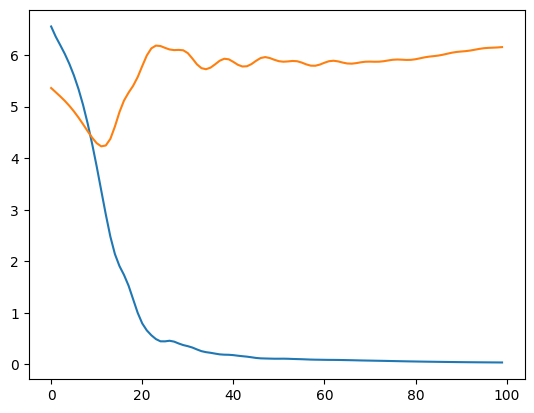

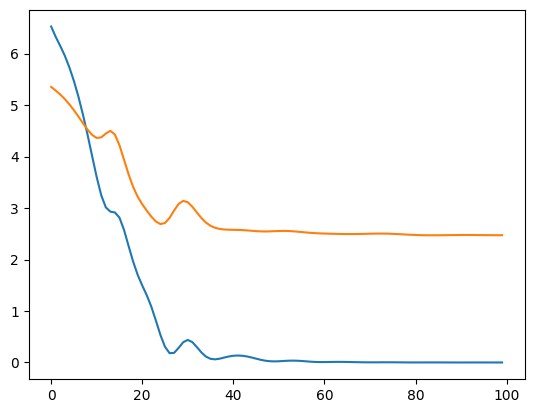

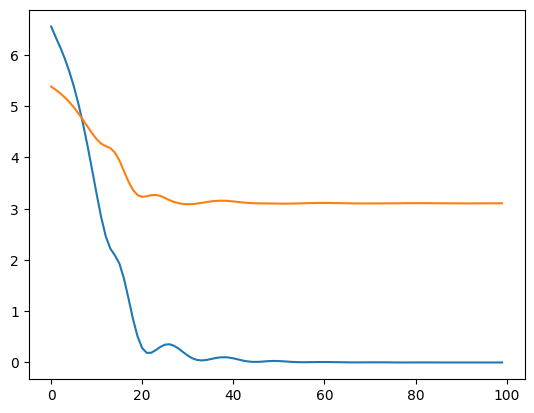

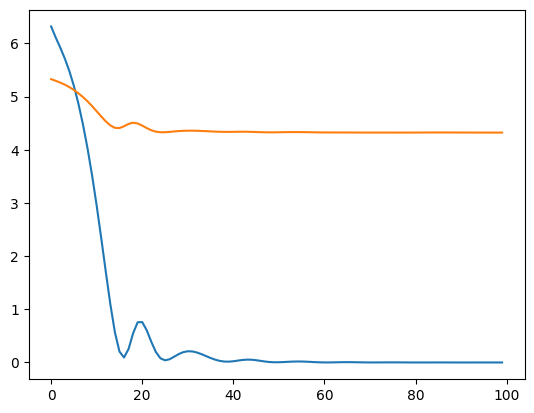

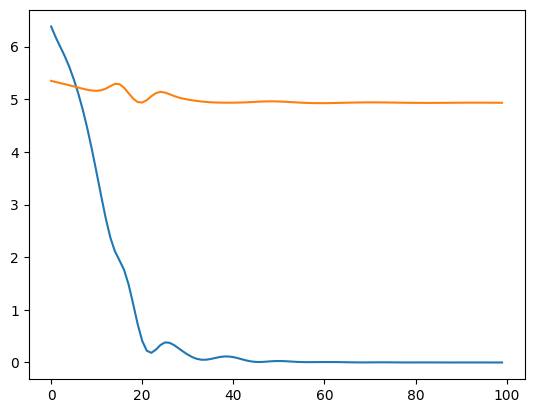

In [5]:
scales = [2., 4., 8., 16., 32.]
models = []
for scale in scales:
    model = RandomFourierFeatures(1, 128, 128, 3, 1, scale=scale)
    optimizer = Adam(params=model.parameters())
    
    epochs = 100
    train_losses = torch.zeros(epochs)
    test_losses = torch.zeros(epochs)

    test_inputs = test_coords.view(-1, 1)
    test_targets = test_values.view(-1, 1)
    inputs = sparse_coords.view(-1, 1)
    targets = sparse_values.view(-1, 1)
    for i in range(epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(inputs)
        train_loss = F.mse_loss(outputs, targets)
        train_losses[i] = train_loss.item()
        train_loss.backward()
        optimizer.step()
        test_outputs = model(test_inputs)
        test_losses[i] = F.mse_loss(test_outputs, test_targets).item()

    models.append(model)
    plt.figure()
    plt.plot(train_losses)
    plt.plot(test_losses)

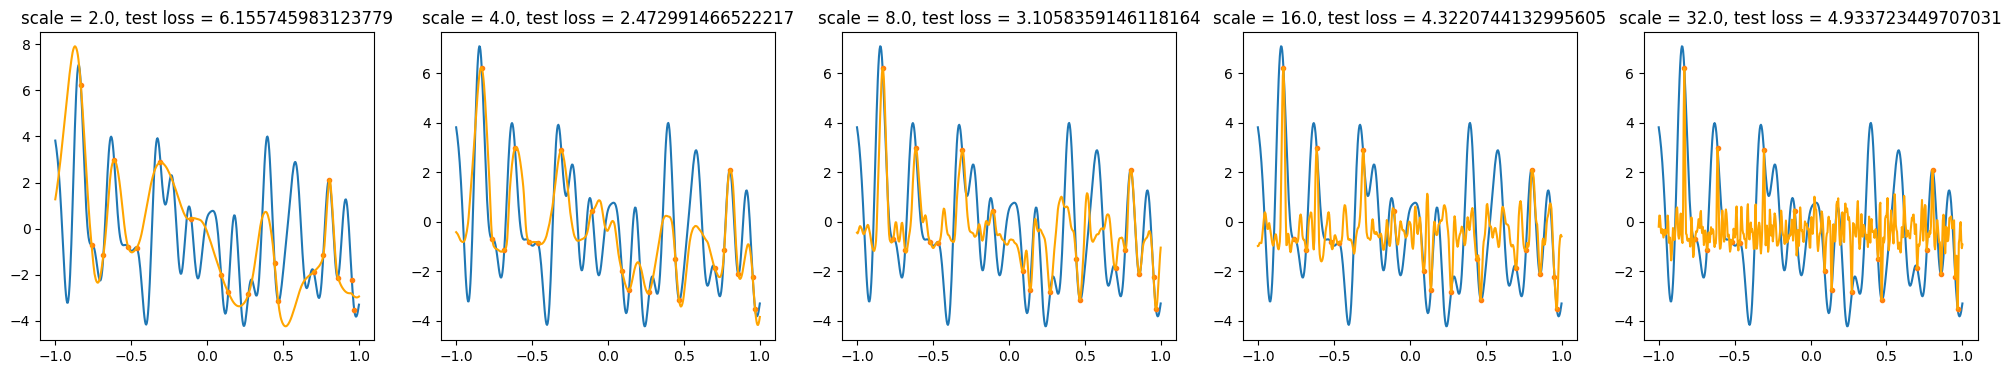

In [6]:
inputs = coords.view(-1, 1)

fig, axes = plt.subplots(1, len(scales), figsize=(5*len(scales), 4))
for i, model in enumerate(models):
    outputs = model(inputs).detach()
    test_outputs = model(test_inputs).detach()
    test_loss = F.mse_loss(test_outputs, test_targets)

    axes[i].plot(coords, combined)
    axes[i].plot(sparse_coords, sparse_values, '.')
    axes[i].plot(coords, outputs.view(512), color="orange")
    axes[i].set_title(f"scale = {scales[i]}, test loss = {test_loss}")

# Other approaches

Simple interpolation, signal reconstruction, guided interpolation?